# Cartera dedicada · Criptomonedas

**Objetivo.** Aislar la clase con mayor volatilidad y con un calendario distinto al de los activos
tradicionales.

- **Universo:** cuatro pares de Kraken: `BTC/USD`, `ETH/USD`, `SOL/USD` y `ADA/USD`, con el mismo peso.
- **Moneda:** USD. El cuaderno mantiene una sola divisa para aislar la clase de activo.
  La biblioteca puede convertir precios cuando se configura `reporting_currency` y se aportan o descargan tipos históricos.
- **Ventana:** desde `2025-01-02` hasta la última vela **cerrada** (se excluye la vela diaria en curso).
- **Anualización:** 365 días, porque el mercado cotiza todos los días.

Kraken solo conserva las últimas 720 velas diarias (≈2 años). La fecha de inicio elegida
(`START = "2025-01-02"`) está dentro de esa ventana; si deja de estarlo, `KrakenSource` lanza un
error explicativo en lugar de devolver una serie truncada. En ese caso, adelanta `START` a una fecha
concreta dentro de los últimos ~700 días (por ejemplo `2026-01-02`) y mantén la misma fecha en los
demás cuadernos para conservar la comparabilidad. La cartera usa el proveedor directo, sin caché CSV:
la nota de retención sustituye a la demo de caché.

Datos hasta la última sesión disponible anterior a `END` (2026-11-06).

El ratio de Sharpe usa `RISK_FREE_RATE = 0.0385` (3,85 % anual) como supuesto fijo del ejercicio.

In [ ]:
"""Cartera dedicada de criptomonedas: ingesta, informe y simulación."""

from IPython.display import Markdown

from quantfolio import KrakenSource, MonteCarloParameters, Portfolio

START = "2025-01-02"
END = "2026-11-06"
TICKERS = ["BTC/USD", "ETH/USD", "SOL/USD", "ADA/USD"]
WEIGHTS = {"BTC/USD": 0.25, "ETH/USD": 0.25, "SOL/USD": 0.25, "ADA/USD": 0.25}
PERIODS_PER_YEAR = 365
RISK_FREE_RATE = 0.0385

## 1 · Ingesta

Kraken expone una API pública OHLC sin clave. `get_many()` descarga los cuatro pares y los normaliza
en `PriceSeries`. El calendario es de siete días: no hay cierre de fin de semana, así que la cartera
tiene 365 observaciones potenciales al año. Kraken solo conserva las últimas 720 velas diarias
(≈2 años); si `START` queda fuera de esa ventana, la fuente lanza un error explicativo en lugar de
devolver una serie truncada. `END` es una fecha fija (`2026-11-06`): todo lo posterior, incluida la
vela en curso, queda excluido de la descarga, así que el resultado no depende del día de ejecución.

In [2]:
source = KrakenSource()
assets = source.get_many(TICKERS, start=START, end=END)

for ticker, asset in assets.items():
    print(
        f"{ticker:>8} | {asset.source:<10} | "
        f"{asset.prices.index.min().date()} → {asset.prices.index.max().date()} | "
        f"{len(asset.prices)} observaciones"
    )

 BTC/USD | Kraken     | 2025-01-02 → 2026-11-05 | 673 observaciones
 ETH/USD | Kraken     | 2025-01-02 → 2026-11-05 | 673 observaciones
 SOL/USD | Kraken     | 2025-01-02 → 2026-11-05 | 673 observaciones
 ADA/USD | Kraken     | 2025-01-02 → 2026-11-05 | 673 observaciones


## 2 · Cartera

`Portfolio` valida que haya un peso por activo, normaliza los pesos y alinea los calendarios por
intersección. La cobertura indica qué fechas conserva el análisis después de esa alineación.

In [3]:
portfolio = Portfolio(assets=assets, weights=WEIGHTS)

print("Pesos normalizados:")
for ticker, weight in portfolio.weights.items():
    print(f"  {ticker}: {weight:.2%}")

print("\nDiagnóstico de alineación temporal:", portfolio.alignment_summary())

Pesos normalizados:
  BTC/USD: 25.00%
  ETH/USD: 25.00%
  SOL/USD: 25.00%
  ADA/USD: 25.00%

Diagnóstico de alineación temporal: {'union_dates': 673, 'common_dates': 673, 'coverage': 1.0, 'multi_day_returns': 0, 'multi_day_share': 0.0, 'max_gap_days': 1}


## 3 · Informe

El informe Markdown reúne la composición, las métricas anualizadas, la calidad de los datos y las
advertencias de riesgo. Las advertencias se calculan a partir del estado real de la cartera.

In [ ]:
Markdown(portfolio.report(risk_free_rate=RISK_FREE_RATE, periods_per_year=PERIODS_PER_YEAR))

## 4 · Panel analítico

El primer panel muestra la evolución de precios **reajustada a base 100**, para que activos con
precios nominales distintos se puedan comparar. Los otros tres paneles muestran la rentabilidad
acumulada, la matriz de correlación y el valor de la cartera.

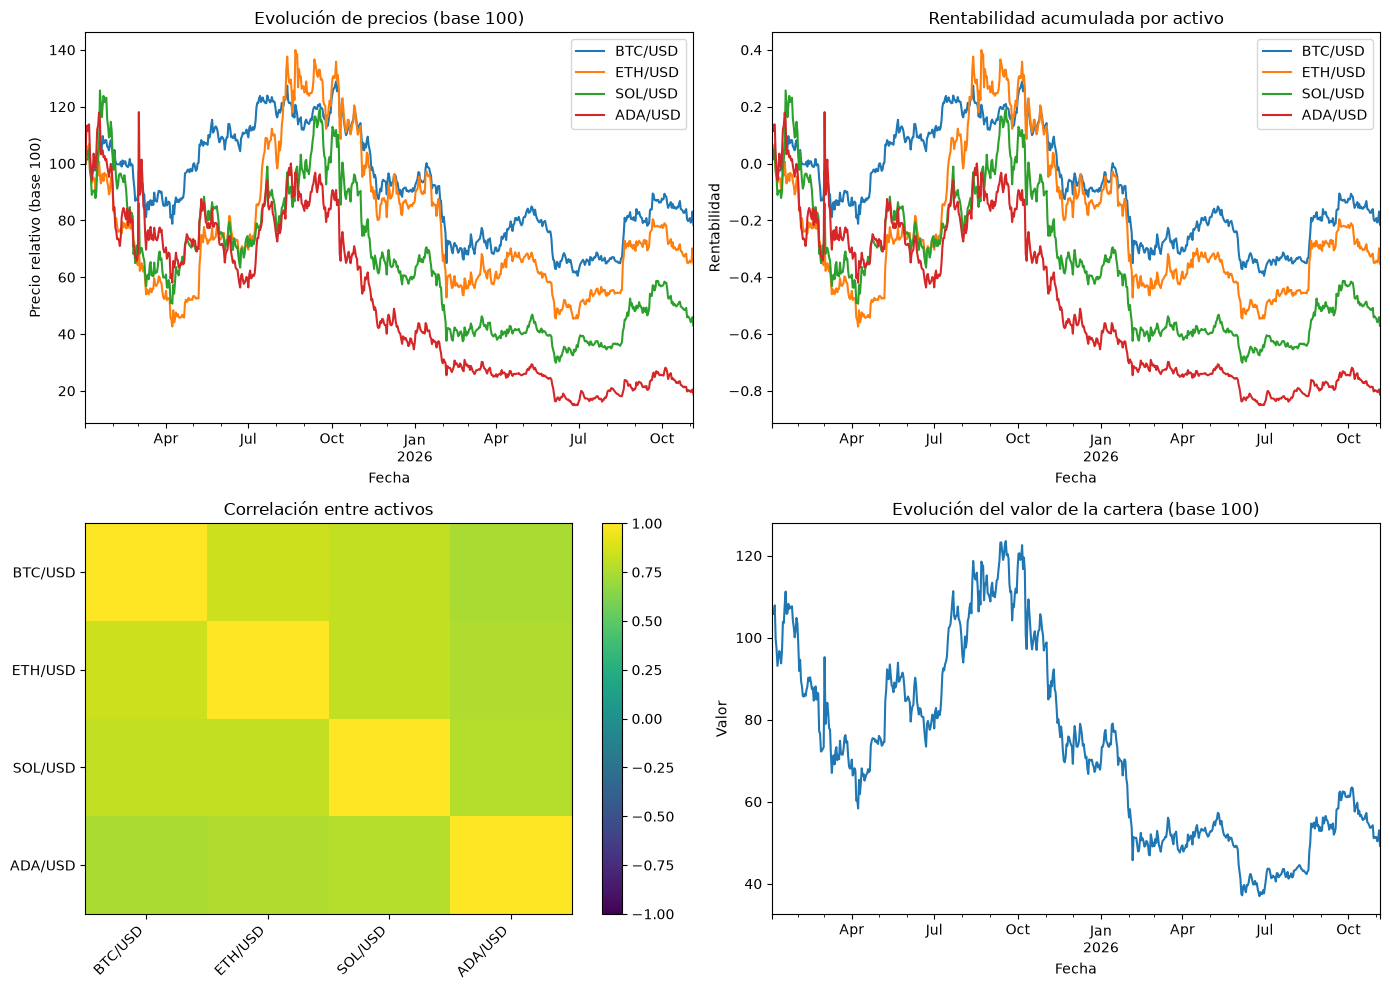

In [5]:
portfolio.plots_report()

## 5 · Simulación Monte Carlo

La simulación usa la deriva y la volatilidad logarítmicas estimadas de la historia. El horizonte
se expresa en los mismos periodos que la anualización de la cartera, de modo que el número de
pasos y los supuestos compartan el mismo calendario. La distribución final permite leer el abanico
de resultados, no una predicción puntual.

count      2000.00
mean       8352.79
std        6541.11
min         848.60
5%         2305.68
50%        6936.17
95%       19825.18
max      131387.58
Name: 365, dtype: float64


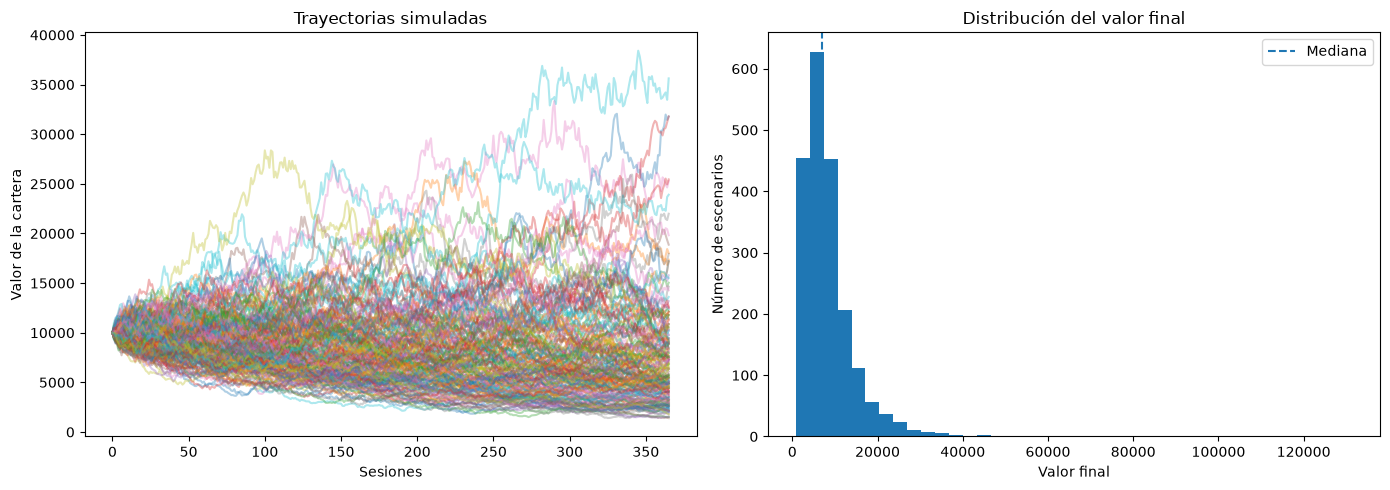

In [6]:
simulations = portfolio.simulate_monte_carlo(
    MonteCarloParameters(
        n_paths=2_000,
        horizon=PERIODS_PER_YEAR,
        periods_per_year=PERIODS_PER_YEAR,
        seed=42,
    )
)

final_values = simulations.iloc[-1]
print(final_values.describe(percentiles=[0.05, 0.5, 0.95]).round(2))
portfolio.plot_simulation(simulations, max_paths=200)

## 6 · Qué aporta esta clase

La cripto es la clase con mayor volatilidad de la cartera y la única que cotiza todos los días. Por
eso se anualiza con 365 periodos, no con 252. Su correlación con la renta variable y la renta fija es
inestable, lo que la convierte en un satélite pequeño más que en un núcleo: aporta diversificación
potencial, pero también colas gruesas y riesgo de liquidez. Al mezclarla con activos de lunes a
viernes, la alineación por intersección descarta sus observaciones de fin de semana.